# Bassez et al. 2021 — Breast Cancer (10x)

**01 — Preprocessing.** Load malignant cells, derive a per-dataset sample threshold, integrate samples with Harmony, build the manifold, remove detached islands, settle sub-region identity (signatures + cell cycle) and judge **Gate 1** (sample-mixing + continuity) on the regenerated embedding.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # Bassez2021_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Bassez2021_Breast | category: Breast


### Load malignant cells
Single leaf matrix directory (UMI counts → `normalize_total` → `log1p`). Malignant label from the publication `cell_type` annotation.

In [3]:
from scripts.load import load_CCCA_adata
adata = load_CCCA_adata(pth_in, verbose=False)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples with malignant cells:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas: (226635, 22567)
malignant: (65885, 22567) | samples with malignant cells: 42
expression: X max 7.92 (log1p of normalize_total UMI counts)


### Sample threshold — data-derived gap-finding
Sort per-sample malignant counts; the largest count ratio marks a spillover cliff. A dominant cliff (top ratio ≥1.5× the runner-up, landing below 2×floor) → geometric-mean threshold; otherwise a floor of 100.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant spillover cliff (3-cell speck) -> geometric-mean threshold = %d' % thresh) if dominant
      else ('no dominant cliff -> floor >= %d' % thresh))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'BIOKEY_26': np.int64(6868), 'BIOKEY_30': np.int64(5650), 'BIOKEY_21': np.int64(4898), 'BIOKEY_35': np.int64(4777), 'BIOKEY_6': np.int64(3336), 'BIOKEY_31': np.int64(3312), 'BIOKEY_17': np.int64(3258), 'BIOKEY_41': np.int64(3164), 'BIOKEY_10': np.int64(3139), 'BIOKEY_9': np.int64(2313), 'BIOKEY_23': np.int64(1996), 'BIOKEY_24': np.int64(1972), 'BIOKEY_1': np.int64(1848), 'BIOKEY_16': np.int64(1837), 'BIOKEY_15': np.int64(1736), 'BIOKEY_12': np.int64(1720), 'BIOKEY_19': np.int64(1417), 'BIOKEY_4': np.int64(1305), 'BIOKEY_7': np.int64(1086), 'BIOKEY_2': np.int64(1050), 'BIOKEY_3': np.int64(977), 'BIOKEY_37': np.int64(908), 'BIOKEY_11': np.int64(826), 'BIOKEY_28': np.int64(796), 'BIOKEY_14': np.int64(666), 'BIOKEY_27': np.int64(600), 'BIOKEY_20': np.int64(580), 'BIOKEY_22': np.int64(556), 'BIOKEY_18': np.int64(542), 'BIOKEY_29': np.int64(415), 'BIOKEY_42': np.int64(377), 'BIOKEY_38': np.int64(288), 'BIOKEY_8': np.int64(276), 'BIOKEY_39': np.int64(253), 'BIOKEY_4

### Genes → PCA → Harmony integration sweep
Overdispersed genes (pagoda2 GAM), 50-PC PCA on the top 20 PCs. Harmony on `sample` swept over θ∈{2,5,10}; mixing read as the mean same-sample fraction among each cell's 30 nearest neighbours (lower = better mixed).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _same_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_frac(adata.obsm['X_pca'][:,:20]); sweep={}
for th in [2,5,10]:
    sce.pp.harmony_integrate(adata,'sample',theta=th,max_iter_harmony=30,random_state=SEED)
    sweep[th] = _same_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k:round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta,
      '(all theta collapse the 0.369 pre-Harmony same-sample fraction to ~0.20 -- metric flat across the sweep;',
      'strongest integration chosen for the strong patient-specific breast batch effect. Gate 1 judged on the embedding, not this scalar.)')
sce.pp.harmony_integrate(adata,'sample',theta=theta,max_iter_harmony=30,random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2498 over-dispersed features (0:00:05) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2498
2026-08-04 19:31:06,937 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-04 19:31:12,311 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-04 19:31:12,856 - harmonypy - INFO - Iteration 1 of 30
2026-08-04 19:31:54,371 - harmonypy - INFO - Iteration 2 of 30
2026-08-04 19:32:34,723 - harmonypy - INFO - Iteration 3 of 30
2026-08-04 19:33:17,243 - harmonypy - INFO - Iteration 4 of 30
2026-08-04 19:34:00,408 - harmonypy - INFO - Iteration 5 of 30
2026-08-04 19:34:23,491 - harmonypy - INFO - Converged after 5 iterations
2026-08-04 19:34:28,416 - harmonypy - INFO - Comp

### Island removal — radius graph, keep the largest component
UMAP radius graph at 6× the median nearest-neighbour distance; keep the largest connected component, re-embed the retained cells.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('manifold after island removal:', adata.shape[0], 'cells')

removed 45 cells in 27 detached islands
manifold after island removal: 65837 cells


### Sub-region identity — **biology before geometry**
Coarse Leiden lobes; per-lobe cycling fraction (publication `cell_cycle_phase`) and a proliferation score. A lobe is scoped out as a **Cycling** compartment only if its cycling fraction is a clear outlier (≥2× the median lobe and ≥10%); otherwise the manifold is a single low-cycling **Body** (Gast confounded by proliferation is the Kürten/Pal failure mode to avoid).

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
cyc_by_lobe = adata.obs.groupby('lobe',observed=True)['cycling'].mean()
prl_by_lobe = adata.obs.groupby('lobe',observed=True)['prolif_score'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc_by_lobe.round(3).to_dict())
print('proliferation score per lobe:', prl_by_lobe.round(3).to_dict())
cyc_lobe = cyc_by_lobe.idxmax()
med = cyc_by_lobe.median()
is_outlier = (cyc_by_lobe.max() >= 2*med) and (cyc_by_lobe.max() >= 0.10) and (prl_by_lobe.idxmax()==cyc_lobe)
if is_outlier:
    adata.obs['compartment'] = np.where(adata.obs['lobe']==cyc_lobe, 'Cycling', 'Body')
    print(f'distinct cycling compartment: lobe {cyc_lobe} ({100*cyc_by_lobe.max():.0f}% cycling, prolif {prl_by_lobe.max():+.2f}) scoped out as Cycling')
else:
    adata.obs['compartment'] = 'Body'
    print(f'no outlier cycling lobe (max {100*cyc_by_lobe.max():.0f}% cycling vs median {100*med:.0f}%); single low-cycling Body')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'0': 19413, '1': 16344, '4': 14182, '5': 9834, '2': 3973, '3': 2091}
cycling fraction per lobe: {'0': 0.034, '1': 0.056, '2': 0.017, '3': 0.02, '4': 0.009, '5': 0.022}
proliferation score per lobe: {'0': -0.033, '1': 0.038, '2': 0.001, '3': -0.039, '4': -0.042, '5': -0.018}
no outlier cycling lobe (max 6% cycling vs median 2%); single low-cycling Body
compartments: {'Body': 65837}


### Embryonic signatures + house orientation
`score_genes` for Gast/pSom/Crest against the union control pool; kNN-graph smoothing for spatial reads (raw scores are the deliverable panels). House linear layout `X_umap_lin`: rigid rotation onto the pSom→Crest biological axis, origin (pSom-high) on the left, shared across all panels.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('pSom vs prolif r = %.2f' % np.corrcoef(adata.obs['pSom'], adata.obs['prolif_score'])[0,1])
xy = adata.obsm['X_umap']; cxy = xy - xy.mean(0)
dfield = adata.obs['Crest_sm'].values - adata.obs['pSom_sm'].values      # increases origin->terminus
u = np.array([np.cov(cxy[:,0], dfield)[0,1], np.cov(cxy[:,1], dfield)[0,1]]); u = u/np.linalg.norm(u)
ang = np.arctan2(u[1], u[0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = cxy @ Rm.T
if np.corrcoef(xyr[:,0], dfield)[0,1] < 0: xyr[:,0] = -xyr[:,0]   # origin -> left
adata.obsm['X_umap_lin'] = xyr
print('house orientation stored as X_umap_lin (pSom origin left, Crest terminus right);',
      'corr(x_lin, Crest-pSom) = %.2f' % np.corrcoef(xyr[:,0], dfield)[0,1])

Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present
raw module means (honest readout): {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.005}
pSom vs prolif r = 0.06
house orientation stored as X_umap_lin (pSom origin left, Crest terminus right); corr(x_lin, Crest-pSom) = 0.68


### Gate 1 — mixing + continuity on the regenerated embedding
Per-neighbourhood iLISI (effective number of samples among 90 neighbours) pre- vs post-Harmony; one connected component after island removal. Verdict read on the embedding (`samples.pdf`), not on the scalar alone.

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (largest connected component).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS'
      + (' (trajectory scoped to the low-cycling Body; Cycling compartment excluded from the fit)'
         if (adata.obs['compartment']=='Cycling').any() else ' (single low-cycling Body)'))

iLISI median: pre-Harmony 5.51 -> post-Harmony(theta=10) 9.10 of 41 samples
41 samples share one continuous manifold (largest connected component).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (single low-cycling Body)


### Save processed manifold

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for col in adata.obs.columns:
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (65837, 22208)


### Figure — sample integration (Gate 1 deliverable, `samples.pdf`)
Single sample-coloured manifold UMAP on the house orientation; intermixing across the strip is the Gate-1 evidence.

saved samples.pdf | cells: 65837 | samples: 41


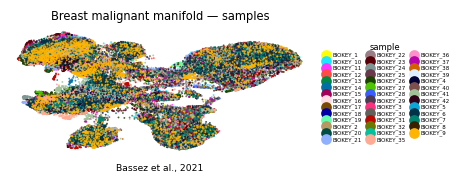

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=3, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.15, fontsize=3.6, columnspacing=.5, title='sample', title_fontsize=5.5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())